# Digits That Matter: Binary Classification of Digit 3

This notebook builds a binary classifier for MNIST: **True = digit 3**, **False = every other digit**. It uses the first 60,000 images for training and the final 10,000 images for testing.

If you are using a fresh Jupyter environment, the first data-loading cell needs internet access to download MNIST from OpenML.

In [1]:
# If needed, install dependencies in a Jupyter cell:
# %pip install -U scikit-learn matplotlib pandas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_score, recall_score, f1_score,
    classification_report, RocCurveDisplay, roc_auc_score, roc_curve
)

RANDOM_STATE = 42

In [2]:
# Download/load the full MNIST dataset (70,000 images, 28x28 pixels).
mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
X = mnist.data.astype(np.float32)
y_digits = mnist.target.astype(np.uint8)

# Required split: first 60,000 train; last 10,000 test.
X_train, X_test = X[:60000], X[60000:]
y_train_digits, y_test_digits = y_digits[:60000], y_digits[60000:]

# Binary labels: True only for digit 3.
y_train = (y_train_digits == 3)
y_test = (y_test_digits == 3)

# Normalize pixel intensities from 0-255 to 0-1.
X_train /= 255.0
X_test /= 255.0

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)
print("Digit 3 training examples:", int(y_train.sum()))
print("Digit 3 test examples:", int(y_test.sum()))

Training images: (60000, 784)
Test images: (10000, 784)
Digit 3 training examples: 6131
Digit 3 test examples: 1010


## Cross-validation predictions on the training set

These predictions are generated out-of-fold, so each training image is predicted by a model that was not trained on that image. This provides a cross-validation estimate separate from the final held-out test evaluation.

In [3]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
model = SGDClassifier(random_state=RANDOM_STATE)

y_train_cv_pred = cross_val_predict(model, X_train, y_train, cv=cv, method="predict", n_jobs=-1)
cv_metrics = {
    "Accuracy": accuracy_score(y_train, y_train_cv_pred),
    "Precision": precision_score(y_train, y_train_cv_pred, zero_division=0),
    "Recall": recall_score(y_train, y_train_cv_pred, zero_division=0),
    "F1 score": f1_score(y_train, y_train_cv_pred, zero_division=0),
}
print("3-fold cross-validation metrics (training data):")
display(pd.DataFrame([cv_metrics], index=["Cross-validation"]).round(4))
print("Cross-validation confusion matrix (rows = actual [False, True], columns = predicted [False, True]):")
display(pd.DataFrame(
    confusion_matrix(y_train, y_train_cv_pred, labels=[False, True]),
    index=["Actual not 3", "Actual 3"],
    columns=["Predicted not 3", "Predicted 3"]
))

3-fold cross-validation metrics (training data):


,Accuracy,Precision,Recall,F1 score
Cross-validation,0.9711,0.8879,0.8206,0.8529


Cross-validation confusion matrix (rows = actual [False, True], columns = predicted [False, True]):


,Predicted not 3,Predicted 3
Actual not 3,53234,635
Actual 3,1100,5031


## Fit on all 60,000 training images and evaluate on the held-out 10,000 images

In [4]:
model.fit(X_train, y_train)
y_test_pred = model.predict(X_test)
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1 score": f1_score(y_test, y_test_pred, zero_division=0),
}
print("Held-out test metrics:")
display(pd.DataFrame([test_metrics], index=["Test set"]).round(4))

cm = confusion_matrix(y_test, y_test_pred, labels=[False, True])
print("Confusion matrix (rows = actual [not 3, 3], columns = predicted [not 3, 3]):")
display(pd.DataFrame(cm, index=["Actual not 3", "Actual 3"],
                     columns=["Predicted not 3", "Predicted 3"]))

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,}; FP={fp:,}; FN={fn:,}; TP={tp:,}")

Held-out test metrics:


,Accuracy,Precision,Recall,F1 score
Test set,0.9755,0.9682,0.7832,0.8659


Confusion matrix (rows = actual [not 3, 3], columns = predicted [not 3, 3]):


,Predicted not 3,Predicted 3
Actual not 3,8964,26
Actual 3,219,791


TN=8,964; FP=26; FN=219; TP=791


ROC AUC: 0.9805


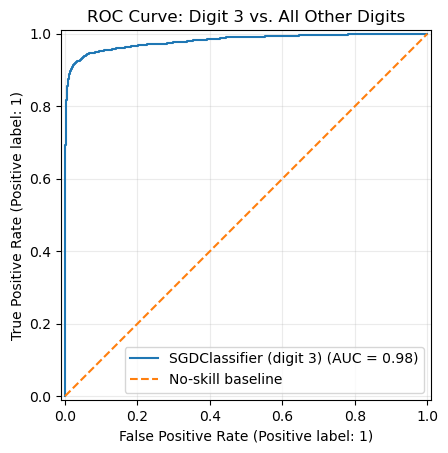

In [5]:
# ROC curve uses the continuous decision score, not hard class predictions.
y_test_scores = model.decision_function(X_test)
auc = roc_auc_score(y_test, y_test_scores)
print(f"ROC AUC: {auc:.4f}")

RocCurveDisplay.from_predictions(y_test, y_test_scores, name="SGDClassifier (digit 3)")
plt.plot([0, 1], [0, 1], linestyle="--", label="No-skill baseline")
plt.title("ROC Curve: Digit 3 vs. All Other Digits")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [6]:
# Which other digits are most often mistaken for a 3?
# False positives are non-3 images predicted as 3.
false_positive_mask = (y_test_pred == True) & (y_test_digits != 3)
fp_digit_counts = pd.Series(y_test_digits[false_positive_mask]).value_counts().sort_values(ascending=False)
print("Actual digit labels among false positives (predicted as 3):")
display(fp_digit_counts.rename_axis("Actual digit").to_frame("False-positive count"))

# False negatives are actual 3s predicted as not 3.
false_negative_mask = (y_test_pred == False) & (y_test_digits == 3)
print(f"False negatives (actual 3 predicted as not 3): {int(false_negative_mask.sum())}")

Actual digit labels among false positives (predicted as 3):


,False-positive count
Actual digit,
5,14
2,8
8,3
1,1


False negatives (actual 3 predicted as not 3): 219


## Threshold tuning (stretch goal)

`SGDClassifier.decision_function` produces scores rather than probabilities. The default decision boundary is 0. Raising the score threshold generally increases precision and lowers recall; lowering it generally increases recall while also increasing false positives.

In [7]:
thresholds = [-1.0, -0.5, 0.0, 0.5, 1.0]
threshold_rows = []
for threshold in thresholds:
    pred_at_threshold = y_test_scores >= threshold
    threshold_rows.append({
        "Decision threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred_at_threshold),
        "Precision": precision_score(y_test, pred_at_threshold, zero_division=0),
        "Recall": recall_score(y_test, pred_at_threshold, zero_division=0),
        "F1 score": f1_score(y_test, pred_at_threshold, zero_division=0),
        "Predicted 3 count": int(pred_at_threshold.sum())
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))

,Decision threshold,Accuracy,Precision,Recall,F1 score,Predicted 3 count
0,-1.0,0.9771,0.8802,0.8950,0.8876,1027
1,-0.5,0.9794,0.9389,0.8515,0.8930,916
2,0.0,0.9755,0.9682,0.7832,0.8659,817
3,0.5,0.9694,0.9835,0.7089,0.8239,728
4,1.0,0.9618,0.9922,0.6267,0.7682,638


## Report notes (use these outputs in your Word document)

- Report the **held-out test** accuracy, precision, recall, and F1 score from the test metrics table.
- Copy the test confusion matrix and identify TN, FP, FN, and TP.
- Interpret ROC AUC: 0.5 is roughly random ranking; values closer to 1 indicate better separation.
- Use the false-positive digit count table to describe which other digits the classifier most often confuses with 3.
- Compare threshold rows to explain how precision and recall change.
- The model is a baseline; real-world use would require testing on handwriting from the intended users and monitoring errors.